# Aula 1 · Parte B: scATAC-seq
## Fragmentos → células → picos → motivos → tópicos

**Curso:** Análise Avançada de Dados de Single-cell RNA-seq, ATAC-seq e Multiome (10x Genomics) no Google Colab
**Ministrante:** Dra. Cristal Villalba · [github.com/kur1sutaru](https://github.com/kur1sutaru)

---

| Etapa | Ferramenta | Conceito-chave |
|---|---|---|
| 1. Importar fragmentos | **SnapATAC2** | o `fragments.tsv.gz` é o dado primário do scATAC |
| 2. QC | TSS enrichment, tamanho de fragmento | nucleossomos deixam "assinatura" na distribuição |
| 3. Matriz de *tiles* + redução | espectral (SnapATAC2) × **TF-IDF + LSI** (Signac/ArchR, via muon) | dados binários e esparsos pedem outra matemática |
| 4. Doublets | Scrublet adaptado ao ATAC | |
| 5. *Gene activity* | acessibilidade no corpo do gene + promotor | ponte para anotar com marcadores de RNA |
| 6. Picos | **MACS3** por tipo celular (pseudobulk) | chamar picos por grupo recupera picos raros |
| 7. Motivos | enriquecimento (SnapATAC2) e **chromVAR** (pychromvar) | qual TF explica a acessibilidade? |
| 8. Tópicos | LDA (o modelo do **cisTopic**) | programas regulatórios sem precisar de clusters |
| 9. Footprinting | coverage por tipo celular → TOBIAS | onde o TF está *de fato* ligado |

**Dados:** PBMC 5k scATAC-seq (10x Genomics), via `snap.datasets.pbmc5k()`.
**Runtime:** CPU basta (≈ 25 min no Colab gratuito, incluindo o download do genoma hg38).

## 0. Instalação 🔧

In [1]:
%pip install -q snapatac2==2.10.0 scanpy==1.12.4 anndata==0.13.4 muon==0.1.9 decoupler==2.2.0 \
    pychromvar==0.0.4 pyjaspar==4.0.0 macs3==3.0.5 scikit-learn==1.7.2 leidenalg==0.12.0 session-info2

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 2.3.3 which is incompatible.


## 1. Imports e parâmetros ⚙️

In [2]:
import os, warnings, random
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc
import snapatac2 as snap
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
sc.settings.set_figure_params(dpi=80, frameon=False, figsize=(4, 4))

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
DATA = Path(os.environ.get("CURSO_DATA", "/content/data" if IN_COLAB else "data"))
OUT = Path(os.environ.get("CURSO_OUT", "/content/resultados" if IN_COLAB else "resultados"))
DATA.mkdir(parents=True, exist_ok=True); OUT.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("SNAP_DATA_DIR", str(DATA / "snapatac2_cache"))   # cache dos downloads do SnapATAC2
print("SnapATAC2", snap.__version__)

SnapATAC2 2.10.0


In [3]:
SEED = 0
MIN_COUNTS = 5000          # fragmentos únicos por célula
MAX_COUNTS = 100_000
MIN_TSSE = 10.0            # TSS enrichment mínimo (ENCODE: > 6 aceitável, > 10 ideal)
N_FEATURES = 250_000       # tiles mais acessíveis usados na redução de dimensão
MACS_QVALUE = 0.05
N_TOPICOS = 15
random.seed(SEED); np.random.seed(SEED)

## 2. Dados 📥
O arquivo de **fragmentos** tem uma linha por fragmento de DNA: `chrom  início  fim  barcode  nº de leituras`.
Tudo no scATAC (matrizes, picos, coverage) é derivado dele, por isso **guarde sempre os fragmentos**.

In [4]:
GENOMA = snap.genome.hg38                      # baixa GTF (GENCODE) e FASTA sob demanda, com cache
FRAGMENTOS = snap.datasets.pbmc5k(type="fragment")

  0%|                                              | 0.00/1.04G [00:00<?, ?B/s]

In [5]:
data = snap.pp.import_fragments(FRAGMENTOS, chrom_sizes=GENOMA, sorted_by_barcode=False,
                                min_num_fragments=500)
data

AnnData object with n_obs × n_vars = 6603 × 0
    obs: 'n_fragment', 'frac_dup', 'frac_mito'
    uns: 'reference_sequences'
    obsm: 'fragment_paired'

## 3. Controle de qualidade
### 3.1 Distribuição do tamanho de fragmentos
Picos em ~50 pb (livre de nucleossomo), ~200 pb (mono-) e ~400 pb (di-nucleossomo).
Sem esse padrão periódico, desconfie da biblioteca.

In [6]:
snap.metrics.frag_size_distr(data)
snap.pl.frag_size_distr(data)

/usr/local/lib/python3.13/dist-packages/kaleido/_sync_server.py:11: UserWarning:




This means that static image generation (e.g. `fig.write_image()`) will not work.

Please upgrade Plotly to version 6.1.1 or greater, or downgrade Kaleido to version 0.2.1.

You can however, use the Kaleido API directly which will work with your plotly version. `kaleido.write_fig(...)`, for example. Please see the kaleido documentation.




### 3.2 TSS enrichment × nº de fragmentos
O **TSSe** mede o sinal nos sítios de início de transcrição em relação ao fundo: é a "razão sinal/ruído" do ATAC.

In [7]:
snap.metrics.tsse(data, GENOMA)
snap.pl.tsse(data)

  0%|                                              | 0.00/35.0M [00:00<?, ?B/s]

In [8]:
snap.pp.filter_cells(data, min_counts=MIN_COUNTS, min_tsse=MIN_TSSE, max_counts=MAX_COUNTS)
print(f"{data.n_obs} células passaram no QC")

4563 células passaram no QC


## 4. Matriz de *tiles* e seleção de *features*
Antes de ter picos, dividimos o genoma em janelas de 500 pb (*tiles*) e contamos inserções do Tn5.
É uma matriz enorme (≈ 6 milhões de colunas), esparsa e quase binária.

In [9]:
snap.pp.add_tile_matrix(data, bin_size=500)
snap.pp.select_features(data, n_features=N_FEATURES)
data

AnnData object with n_obs × n_vars = 4563 × 6062095
    obs: 'n_fragment', 'frac_dup', 'frac_mito', 'tsse'
    var: 'count', 'selected'
    uns: 'reference_sequences', 'frag_size_distr', 'library_tsse', 'frac_overlap_TSS', 'TSS_profile'
    obsm: 'fragment_paired'
    layers: None (.X)

## 5. Doublets no ATAC
Mesmo princípio do Scrublet de RNA, aplicado à matriz de tiles. Doublets de ATAC também aparecem como células
com **número de fragmentos anormalmente alto**.

In [10]:
snap.pp.scrublet(data, random_state=SEED)
snap.pp.filter_doublets(data)
print(f"{data.n_obs} células após remover doublets")

4428 células após remover doublets


## 6. Redução de dimensão: duas filosofias

| | **SnapATAC2 (espectral)** | **TF-IDF + LSI** (Signac, ArchR, muon, episcanpy) |
|---|---|---|
| Ideia | grafo de similaridade cosseno entre células → autovetores do Laplaciano | normaliza (TF-IDF) e faz SVD truncada |
| 1º componente | — | correlaciona com profundidade → **descartar** |
| Escala | amostragem de Nyström para milhões de células | memória cresce com a matriz |

Vamos rodar as duas e comparar.

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



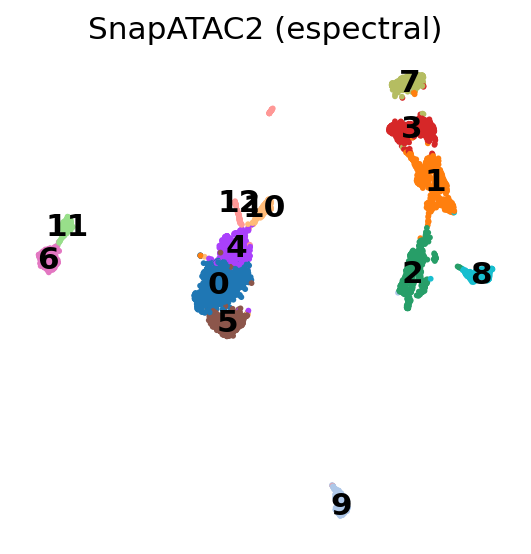

In [11]:
snap.tl.spectral(data, random_state=SEED)
snap.tl.umap(data, random_state=SEED)
snap.pp.knn(data)
snap.tl.leiden(data, random_state=SEED)
sc.pl.embedding(data, basis="X_umap", color="leiden", title="SnapATAC2 (espectral)", legend_loc="on data")

correlação LSI_1 × log(profundidade): -0.95  → descartamos o 1º componente


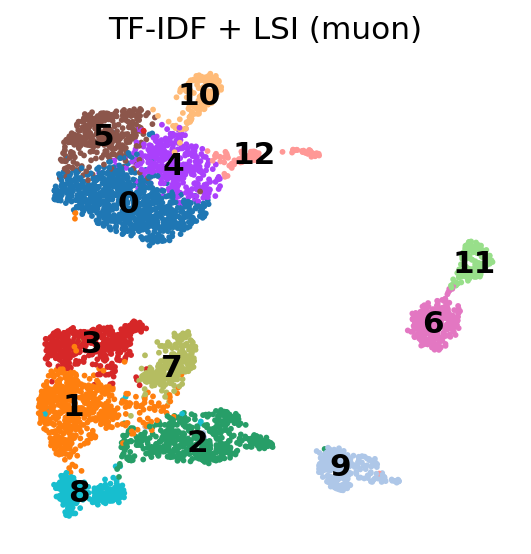

In [12]:
import muon as mu

lsi = data[:, data.var["selected"].values].copy()
lsi.X = (lsi.X > 0).astype(np.float32)                        # binarizar
mu.atac.pp.tfidf(lsi, scale_factor=1e4)
mu.atac.tl.lsi(lsi, n_comps=31)
depth = np.asarray(data.obs["n_fragment"])
r1 = np.corrcoef(lsi.obsm["X_lsi"][:, 0], np.log1p(depth))[0, 1]
print(f"correlação LSI_1 × log(profundidade): {r1:.2f}  → descartamos o 1º componente")
lsi.obsm["X_lsi"] = lsi.obsm["X_lsi"][:, 1:]
sc.pp.neighbors(lsi, use_rep="X_lsi", random_state=SEED)
sc.tl.umap(lsi, random_state=SEED)
lsi.obs["leiden_snap"] = data.obs["leiden"].values
sc.pl.umap(lsi, color="leiden_snap", title="TF-IDF + LSI (muon)", legend_loc="on data")

In [13]:
from sklearn.metrics import adjusted_rand_score
sc.tl.leiden(lsi, key_added="leiden_lsi", random_state=SEED, flavor="igraph", n_iterations=2, directed=False)
print(f"ARI entre clusters espectral × LSI: {adjusted_rand_score(data.obs['leiden'], lsi.obs['leiden_lsi']):.2f}")

ARI entre clusters espectral × LSI: 0.75


### E o episcanpy? Uma lição de manutenção de software 🧰
O `episcanpy` (0.4.0) ainda é muito citado, mas **não importa** com `numpy ≥ 2` nem com `anndata ≥ 0.11`:
usa `np.NaN` e `anndata.read`, que foram removidos. A célula abaixo mostra o erro e o "remendo" (*shim*).
Remendos funcionam para demonstração, mas **não use em produção**: prefira ferramentas mantidas (SnapATAC2, muon).

In [ ]:
try:
    import episcanpy  # noqa: F401
    print("episcanpy importou sem remendo")
except Exception as e:
    print(f"❌ {type(e).__name__}: {e}")
    import anndata
    np.NaN = np.nan                         # shim 1
    anndata.read = anndata.read_h5ad        # shim 2
    try:
        import episcanpy as epi
        print("✅ episcanpy", epi.__version__, "importou com remendos")
    except Exception as e2:
        print("ainda falha:", e2)

## 7. *Gene activity* e anotação
Somamos as inserções no corpo do gene + 2 kb a montante. Esse proxy de expressão permite usar **marcadores de RNA**.

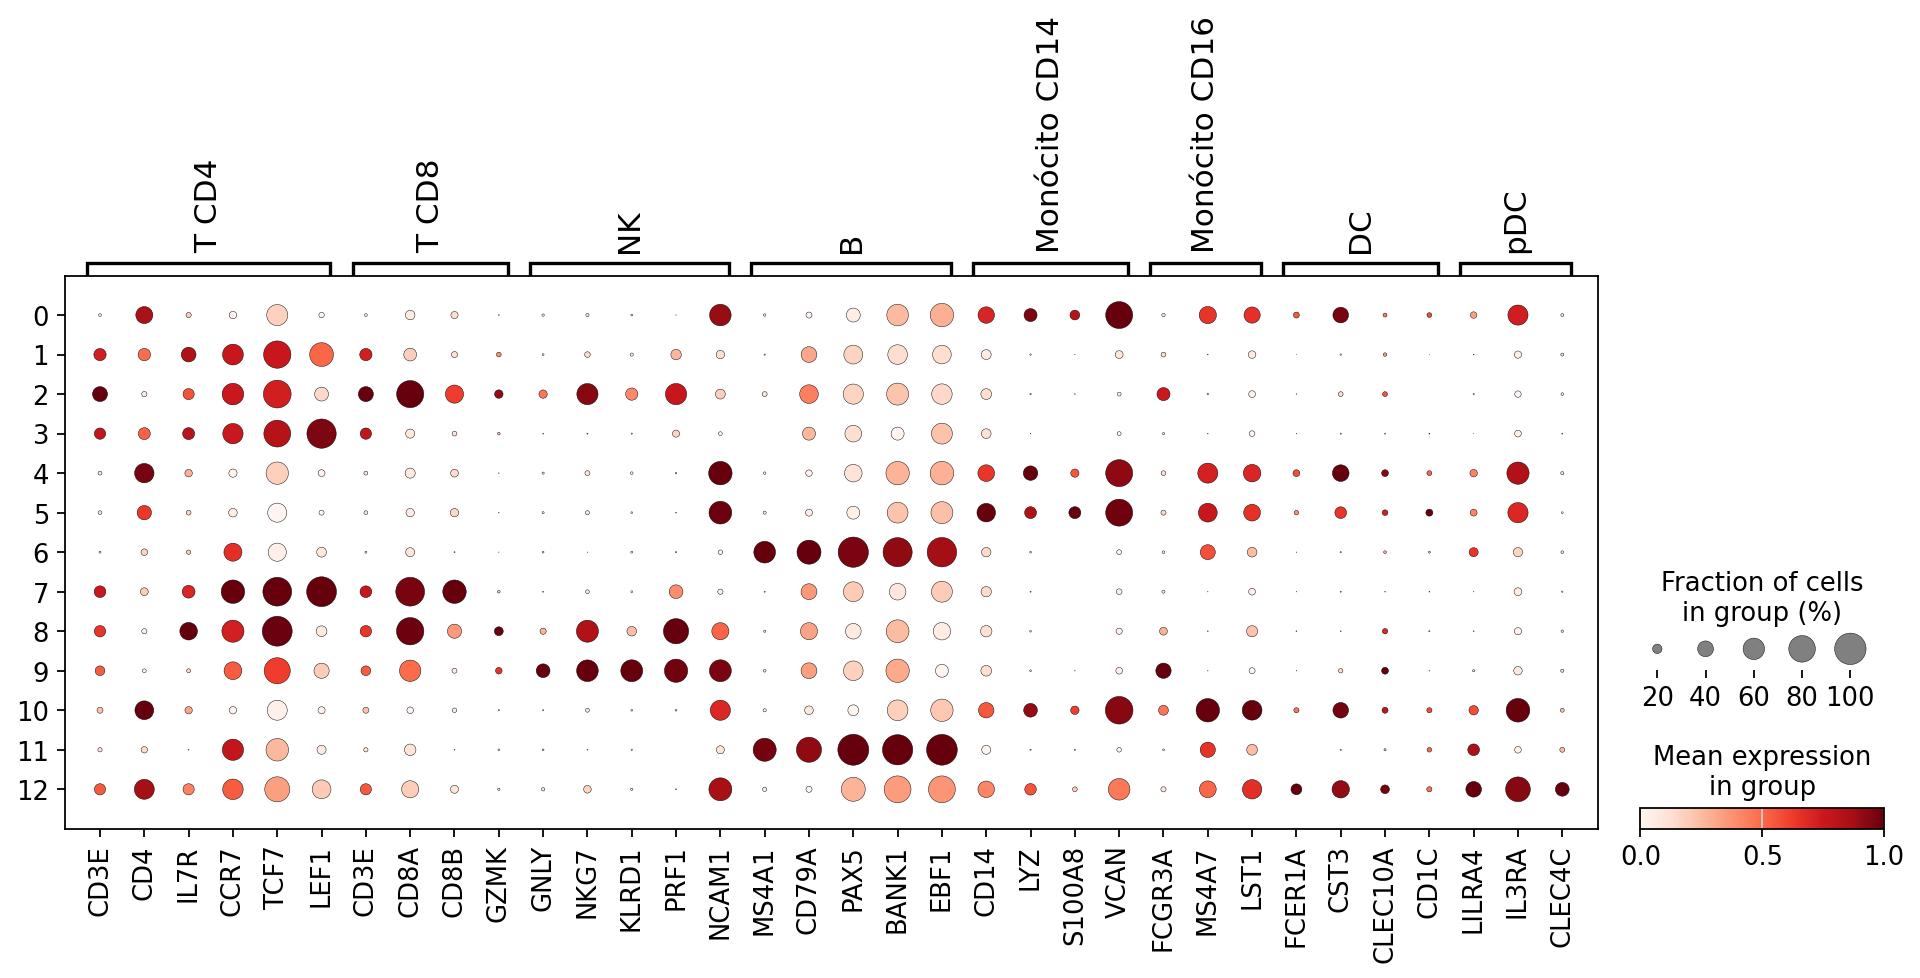

In [14]:
gene_mat = snap.pp.make_gene_matrix(data, GENOMA)
sc.pp.filter_genes(gene_mat, min_cells=5)
sc.pp.normalize_total(gene_mat)
sc.pp.log1p(gene_mat)
gene_mat.obsm["X_umap"] = data.obsm["X_umap"]
gene_mat.obs["leiden"] = data.obs["leiden"].values

MARCADORES = {
    "T CD4": ["CD3E", "CD4", "IL7R", "CCR7", "TCF7", "LEF1"],
    "T CD8": ["CD3E", "CD8A", "CD8B", "GZMK"],
    "NK": ["GNLY", "NKG7", "KLRD1", "PRF1", "NCAM1"],
    "B": ["MS4A1", "CD79A", "PAX5", "BANK1", "EBF1"],
    "Monócito CD14": ["CD14", "LYZ", "S100A8", "VCAN"],
    "Monócito CD16": ["FCGR3A", "MS4A7", "LST1"],
    "DC": ["FCER1A", "CST3", "CLEC10A", "CD1C"],
    "pDC": ["LILRA4", "IL3RA", "CLEC4C"],
}
sc.pl.dotplot(gene_mat, {k: [g for g in v if g in gene_mat.var_names] for k, v in MARCADORES.items()},
              groupby="leiden", standard_scale="var")

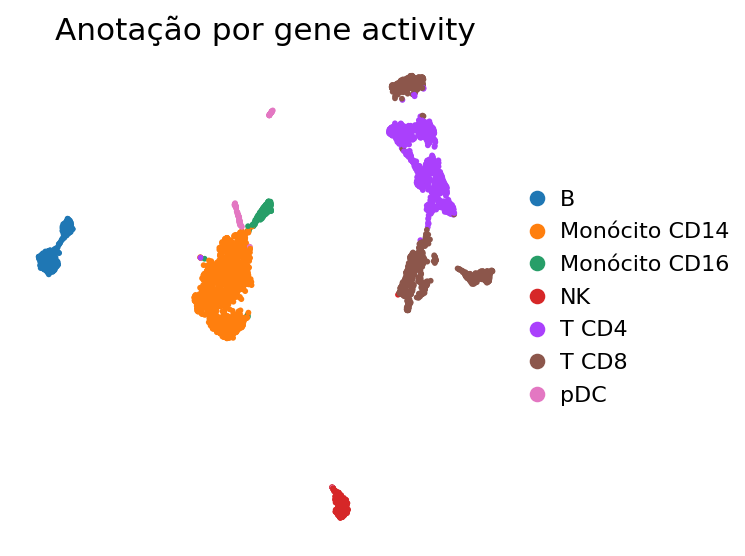

In [15]:
import decoupler as dc
net = pd.DataFrame([(k, g) for k, v in MARCADORES.items() for g in v], columns=["source", "target"])
dc.mt.ulm(gene_mat, net, tmin=2)
scores = dc.pp.get_obsm(gene_mat, key="score_ulm")
rank = dc.tl.rankby_group(scores, groupby="leiden", reference="rest", method="t-test_overestim_var")
rotulo = rank[rank["stat"] > 0].groupby("group").head(1).set_index("group")["name"]
data.obs["cell_type"] = data.obs["leiden"].astype(str).map(rotulo.astype(str).to_dict()).fillna("indefinido").astype("category")
gene_mat.obs["cell_type"] = data.obs["cell_type"].values
sc.pl.embedding(data, basis="X_umap", color="cell_type", title="Anotação por gene activity")

> ⚠️ *Gene activity* é **ruidoso**: genes muito longos acumulam sinal e genes regulados por enhancers distais
> ficam subestimados. Em dados Multiome você terá o RNA verdadeiro (Aula 2).

## 8. Chamada de picos com MACS3 (por tipo celular)
O MACS2 da ementa foi sucedido pelo **MACS3** (mesmo algoritmo, mantido, Python 3). O SnapATAC2 chama picos
**por grupo** (pseudobulk): picos de tipos raros (ex.: pDC) seriam diluídos num *bulk* único.
Depois, os picos são **unificados** em janelas fixas de 501 pb (estilo ArchR, *iterative overlap*).

In [16]:
snap.tl.macs3(data, groupby="cell_type", qvalue=MACS_QVALUE)
picos = snap.tl.merge_peaks(data.uns["macs3"], GENOMA)
print(f"{picos.shape[0]} picos unificados"); picos.head()

100%|██████████| 7/7 [19:41<00:00, 168.78s/it]


168813 picos unificados


Peaks,Monócito CD16,T CD8,Monócito CD14,pDC,B,NK,T CD4
str,bool,bool,bool,bool,bool,bool,bool
"""chr1:180653-181154""",true,false,true,false,false,true,true
"""chr1:181202-181703""",false,true,false,false,false,false,false
"""chr1:191590-192091""",false,true,true,false,false,true,false
"""chr1:267749-268250""",false,true,true,true,false,false,true
"""chr1:280472-280973""",false,false,true,false,false,false,false


In [17]:
peak_mat = snap.pp.make_peak_matrix(data, use_rep=picos["Peaks"])
peak_mat.obs["cell_type"] = data.obs["cell_type"].values
peak_mat.write_h5ad(OUT / "aula1_atac_picos.h5ad", compression="gzip")
peak_mat

AnnData object with n_obs × n_vars = 4428 × 168813
    obs: 'n_fragment', 'frac_dup', 'frac_mito', 'tsse', 'doublet_probability', 'doublet_score', 'leiden', 'cell_type'
    layers: None (.X)

## 9. Motivos de fatores de transcrição
### 9.1 Enriquecimento de motivos em picos marcadores (SnapATAC2)
Pergunta: **quais motivos estão super-representados nos picos específicos de cada tipo celular?**
Motivos: CIS-BP (Weirauch et al. 2014), versão não redundante distribuída com o SnapATAC2.

In [18]:
MOTIVOS_SNAP = snap.datasets.cis_bp(unique=True)

  0%|                                              | 0.00/2.78M [00:00<?, ?B/s]

In [19]:
picos_marcadores = snap.tl.marker_regions(peak_mat, groupby="cell_type", pvalue=0.01)
{k: len(v) for k, v in picos_marcadores.items()}

{'T CD8': 81,
 'Monócito CD14': 945,
 'T CD4': 138,
 'B': 2626,
 'pDC': 4362,
 'Monócito CD16': 1103,
 'NK': 1254}

In [20]:
enriq = snap.tl.motif_enrichment(motifs=MOTIVOS_SNAP, regions=picos_marcadores,
                                 genome_fasta=GENOMA, method="hypergeometric")
snap.pl.motif_enrichment(enriq, max_fdr=0.01, min_log_fc=0.5, height=900)

  0%|                                               | 0.00/845M [00:00<?, ?B/s]

Decompressing '/content/data/snapatac2_cache/snapatac2/gencode_v41_GRCh38.fa.gz' to '/content/data/snapatac2_cache/snapatac2/gencode_v41_GRCh38.fa.gz.decomp' using method 'gzip'.
100%|██████████| 1165/1165 [13:54<00:00,  1.40it/s]


In [21]:
top_motivos = pd.concat([
    df.to_pandas().assign(cell_type=ct).sort_values("adjusted p-value").head(5)
    for ct, df in enriq.items()])
top_motivos[["cell_type", "id", "name", "log2(fold change)", "adjusted p-value"]]

,cell_type,id,name,log2(fold change),adjusted p-value
18,T CD8,ARX+M00260_2.00,ARX,2.793420,7.497974e-02
228,T CD8,GABPA+M10504_2.00,GABPA,3.734086,1.278209e-01
644,T CD8,RORA+M11091_2.00,RORA,2.495926,2.584857e-01
639,T CD8,RFX7+M05729_2.00,RFX7,3.904011,2.939621e-01
780,T CD8,THAP1+M08020_2.00,THAP1,2.547000,3.789656e-01
32,Monócito CD14,BACH2+M08065_2.00,BACH2,2.010281,3.103659e-32
60,Monócito CD14,CEBPA+M08076_2.00,CEBPA,2.072203,4.718748e-32
488,Monócito CD14,NFE2L2+M08789_2.00,NFE2L2,2.008702,1.065281e-31
31,Monócito CD14,BACH1+M09488_2.00,BACH1,1.996333,1.065281e-31
178,Monócito CD14,FOSL2+M07812_2.00,FOSL2,1.989740,2.052374e-28


### 9.2 chromVAR: atividade de motivos **por célula**
O chromVAR (Schep et al., *Nat Methods* 2017) pergunta, para cada célula: *os picos com o motivo X estão mais
acessíveis do que o esperado?* O "esperado" vem de **picos de fundo** com o mesmo GC e a mesma acessibilidade média.
A saída é um *z-score* de desvio por motivo e por célula. Usamos o `pychromvar` (port para Python) e motivos do **JASPAR 2024**.

In [22]:
from pyjaspar import jaspardb
MOTIVOS_JASPAR = jaspardb(release="JASPAR2024").fetch_motifs(collection="CORE", tax_group=["vertebrates"])
print(len(MOTIVOS_JASPAR), "motivos JASPAR")

879 motivos JASPAR


In [23]:
import pychromvar as pc

cv = peak_mat.copy()
cv = cv[:, np.asarray(cv.X.sum(0)).ravel() > 0].copy()
cv.X = cv.X.astype(np.float32)          # pychromvar 0.0.4 falha com contagens inteiras (divisão in-place)
pc.add_peak_seq(cv, genome_file=str(GENOMA.fasta), delimiter="[:-]")
pc.add_gc_bias(cv)
pc.get_bg_peaks(cv, niterations=50)
pc.match_motif(cv, motifs=MOTIVOS_JASPAR)

# ⚠️ `pc.compute_deviations` (0.0.4) densifica a matriz, copia-a para cada processo e chama
# `AnnData(..., dtype=)`, removido no anndata 0.11. Reimplementamos o mesmo cálculo de forma ESPARSA,
# usando os picos de fundo e os matches que o pychromvar já calculou:
#   desvio(c, m) = (obs - esperado) / esperado,   esperado = profundidade(c) × fração do pico na amostra
#   z(c, m)      = (desvio - média_fundo) / dp_fundo
import anndata as ad
import scipy.sparse as sp

def chromvar_desvios(adata) -> ad.AnnData:
    X = sp.csr_matrix(adata.X, dtype=np.float32)
    M = sp.csr_matrix(np.asarray(adata.varm["motif_match"]), dtype=np.float32)   # picos × motivos
    prof = np.asarray(X.sum(1)).ravel()
    frac = np.asarray(X.sum(0)).ravel() / X.sum()

    def desvio(Mx):
        obs = (X @ Mx).toarray()
        esp = np.outer(prof, Mx.T @ frac)
        with np.errstate(divide="ignore", invalid="ignore"):
            return (obs - esp) / esp

    d_obs = desvio(M)
    bg = np.asarray(adata.varm["bg_peaks"])
    s1 = np.zeros_like(d_obs); s2 = np.zeros_like(d_obs)
    for i in range(bg.shape[1]):
        d = desvio(M[bg[:, i]])
        s1 += d; s2 += d ** 2
    media = s1 / bg.shape[1]
    dp = np.sqrt(np.maximum(s2 / bg.shape[1] - media ** 2, 0))
    with np.errstate(divide="ignore", invalid="ignore"):
        z = np.nan_to_num((d_obs - media) / dp, nan=0.0, posinf=0.0, neginf=0.0)
    return ad.AnnData(z.astype(np.float32), obs=pd.DataFrame(index=adata.obs_names),
                      var=pd.DataFrame(index=adata.uns["motif_name"]))

desvios = chromvar_desvios(cv)
desvios.obs["cell_type"] = peak_mat.obs["cell_type"].values
desvios.obsm["X_umap"] = data.obsm["X_umap"]
desvios

100%|██████████| 168813/168813 [03:46<00:00, 745.50it/s]


AnnData object with n_obs × n_vars = 4428 × 879
    obs: 'cell_type'
    obsm: 'X_umap'
    layers: None (.X)

motivos mais variáveis: ['MA0081.3.SPIB', 'MA0080.7.Spi1', 'MA0687.2.SPIC', 'MA0102.5.CEBPA', 'MA1636.2.CEBPG', 'MA0462.3.BATF::JUN']


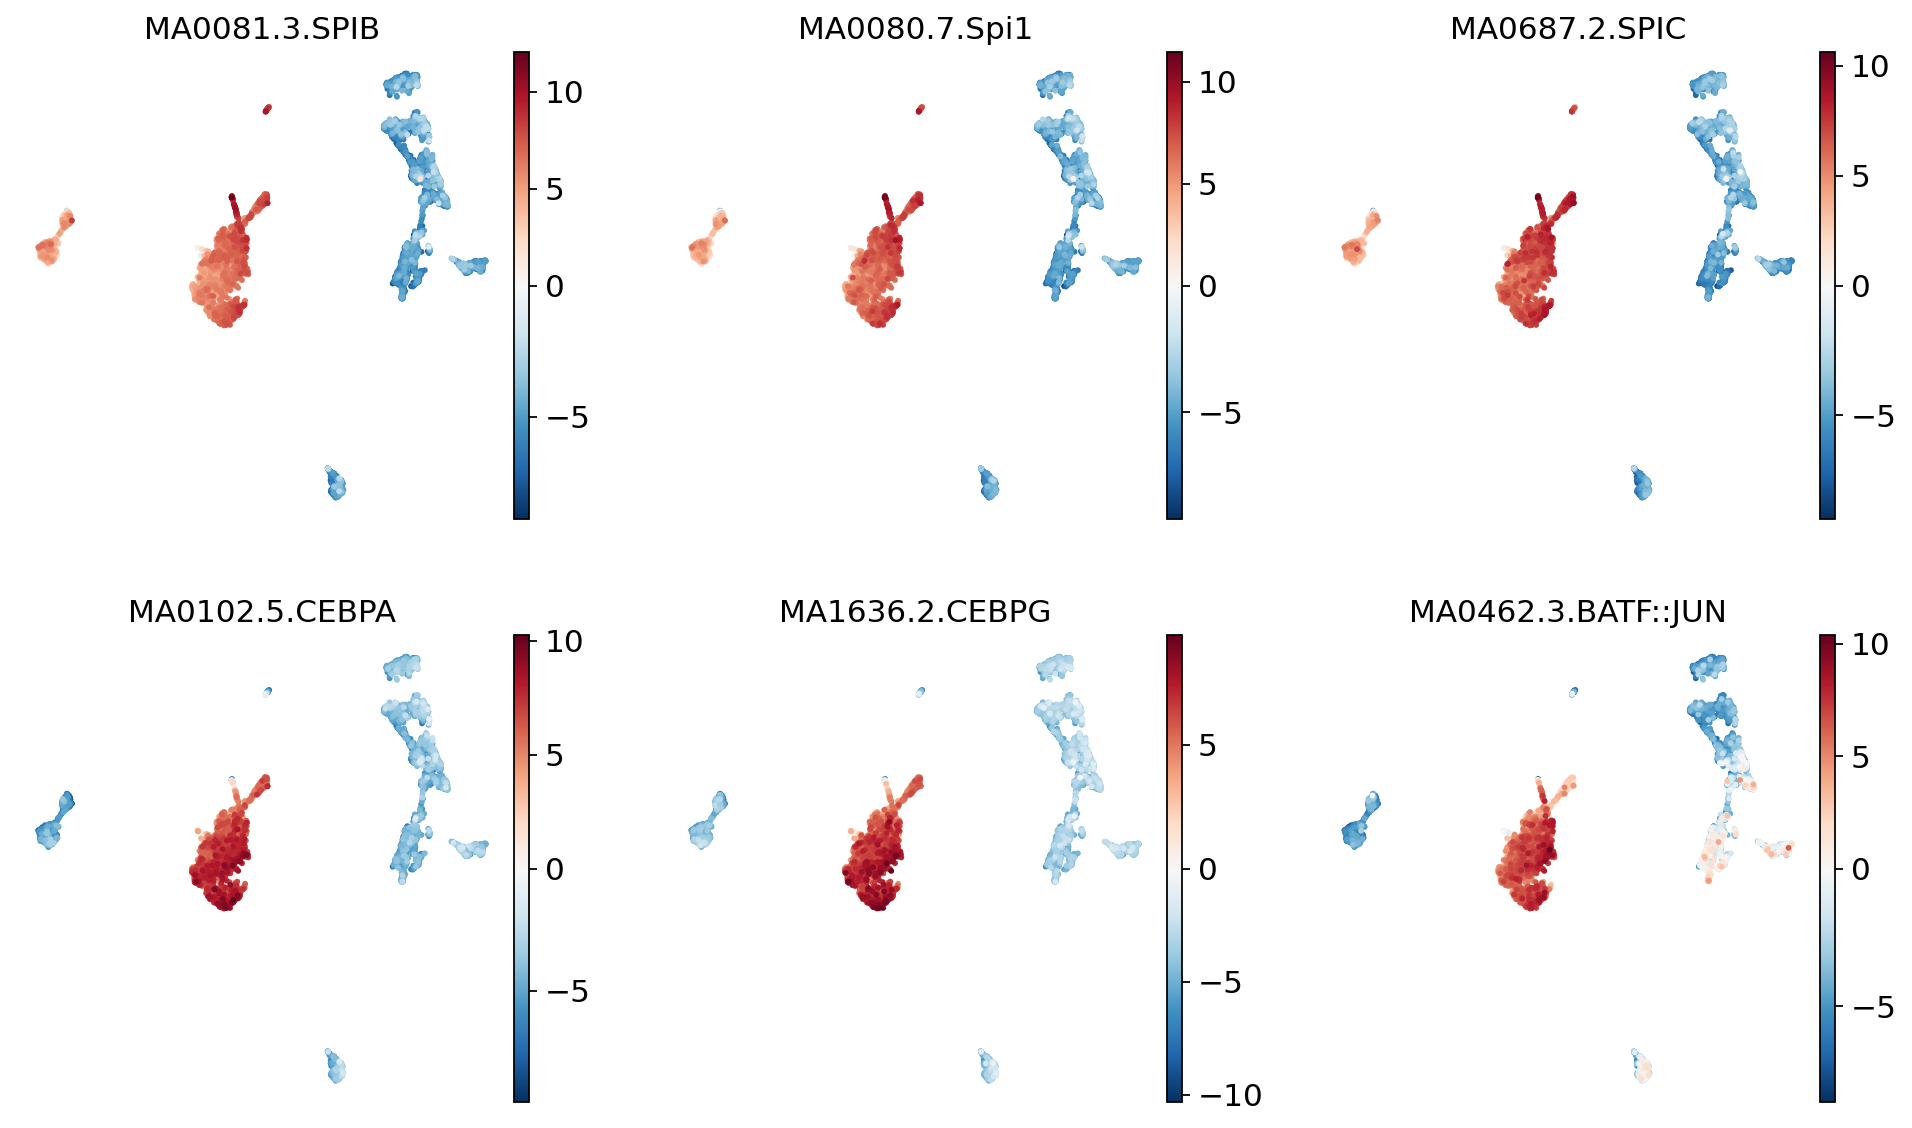

In [24]:
var_mot = pd.Series(np.nan_to_num(np.asarray(desvios.X)).std(0), index=desvios.var_names).sort_values(ascending=False)
top = var_mot.index[:6].tolist()
print("motivos mais variáveis:", top)
desvios.X = np.nan_to_num(np.asarray(desvios.X))
sc.pl.embedding(desvios, basis="X_umap", color=top, cmap="RdBu_r", vcenter=0, ncols=3)

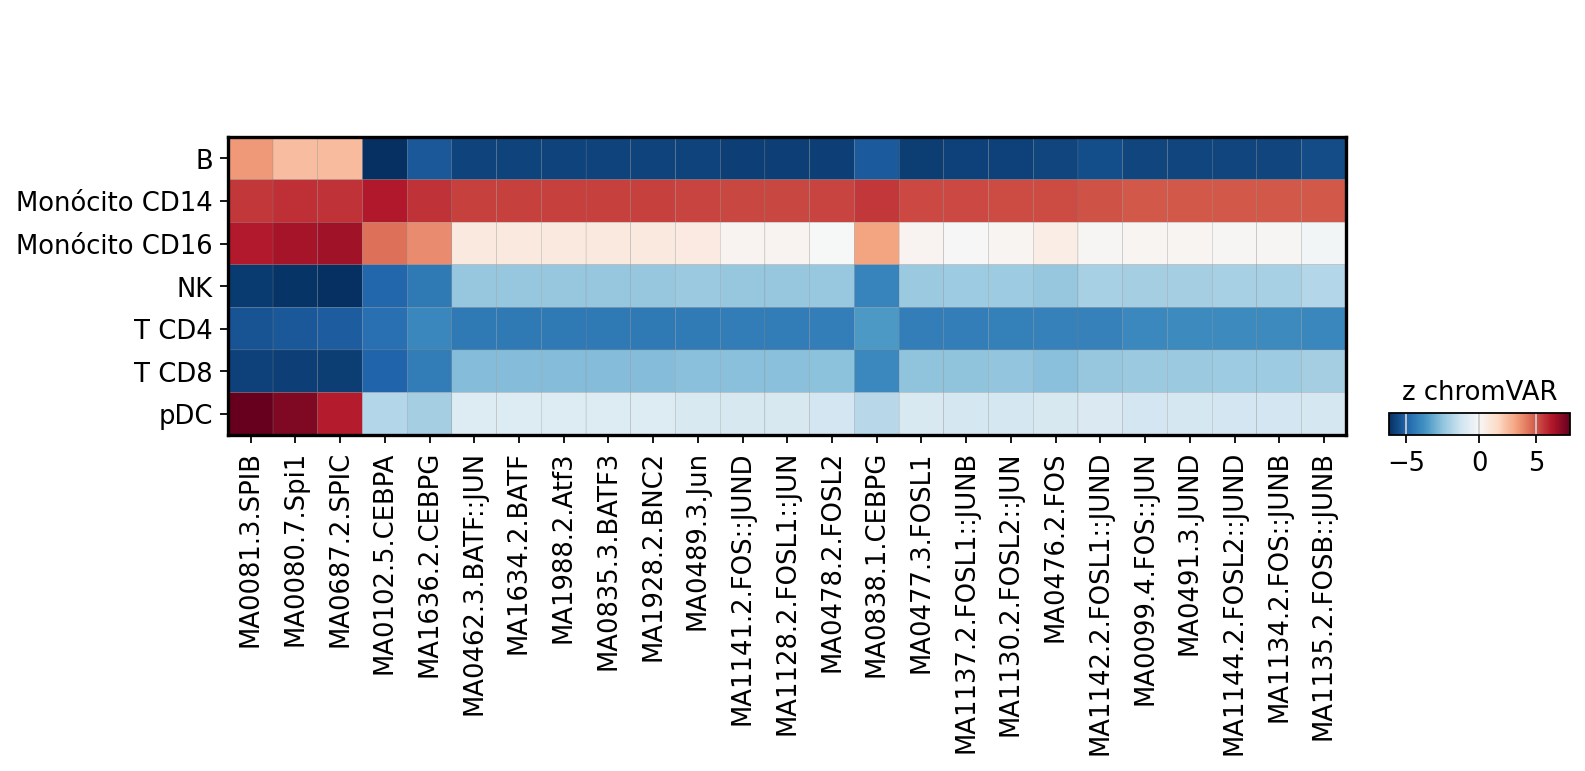

In [25]:
sc.pl.matrixplot(desvios, var_names=var_mot.index[:25].tolist(), groupby="cell_type",
                 cmap="RdBu_r", vcenter=0, colorbar_title="z chromVAR")

> 💬 Esperado em PBMC: **SPI1/PU.1** e **CEBP** em monócitos, **PAX5/EBF1** em B, **TBX21/EOMES** em NK/CD8,
> **TCF7/LEF1** em T naive. Motivos da **mesma família** (ex.: todos os ETS) dão sinais quase idênticos:
> o chromVAR identifica a família, não o membro. Para isso, cruze com o RNA (Aula 2).

## 10. Modelagem de tópicos (o modelo do cisTopic)
O **cisTopic/pycisTopic** (Bravo González-Blas et al., *Nat Methods* 2019) aplica **LDA**
(*Latent Dirichlet Allocation*) à matriz binária célula × pico:
- cada **célula** é uma mistura de **tópicos**;
- cada **tópico** é uma distribuição sobre **regiões** (um "programa regulatório").

O pycisTopic usa amostragem de Gibbs (Mallet) e é a entrada do SCENIC+. Ele exige Python 3.11 e não roda bem no Colab
gratuito (veja a Aula 2). Aqui usamos a **mesma família de modelo** (LDA variacional, `scikit-learn`) para entender o conceito.

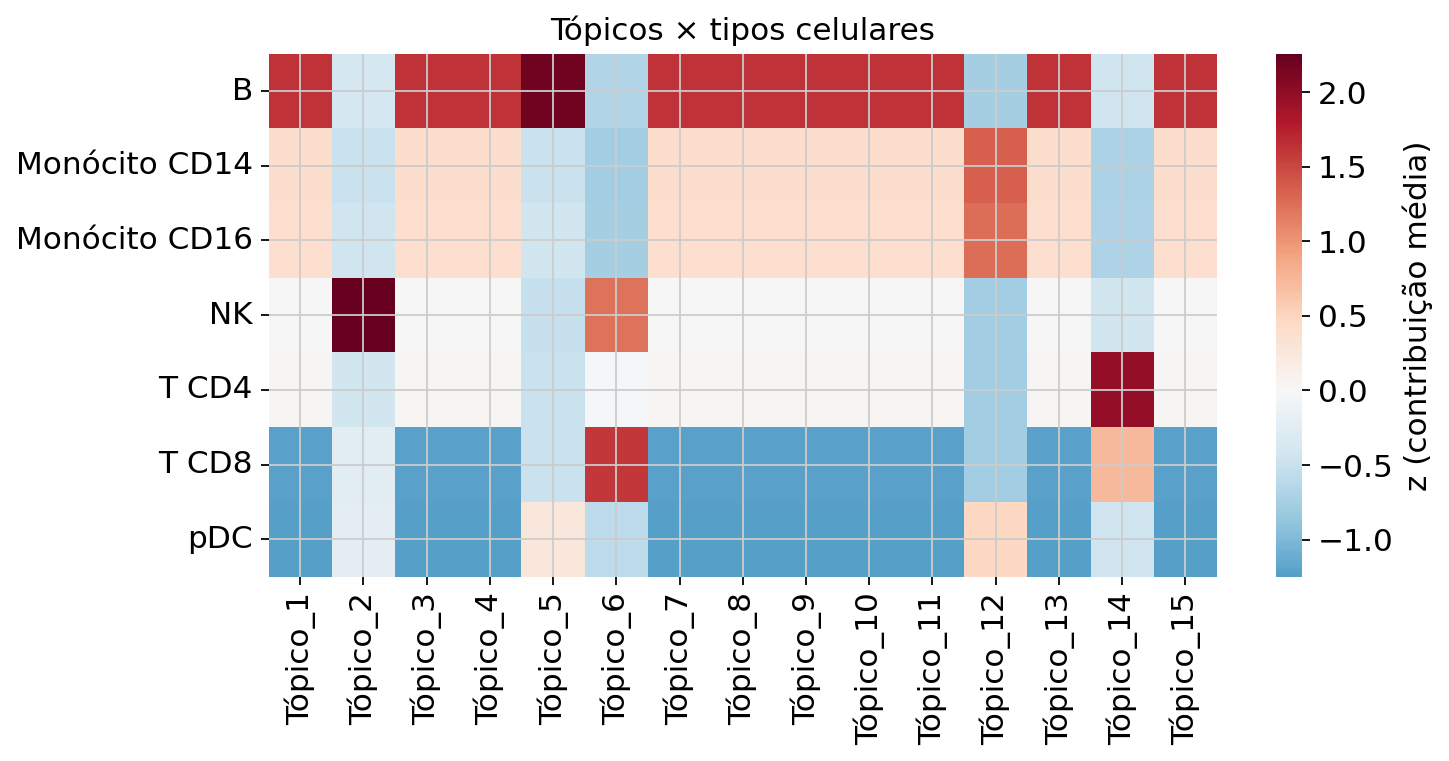

In [26]:
from sklearn.decomposition import LatentDirichletAllocation
import scipy.sparse as sp

Xb = (peak_mat.X > 0).astype(np.float32)
frac = np.asarray(Xb.mean(0)).ravel()
keep = np.argsort(-np.where((frac > 0.01) & (frac < 0.6), frac, 0))[:20000]   # picos informativos
keep = keep[frac[keep] > 0]
Xt = sp.csr_matrix(Xb[:, keep])

lda = LatentDirichletAllocation(n_components=N_TOPICOS, learning_method="online", batch_size=512,
                                max_iter=15, random_state=SEED, n_jobs=-1)
theta = lda.fit_transform(Xt)                         # células × tópicos
peak_mat.obsm["X_topicos"] = theta
topicos = pd.DataFrame(theta, index=peak_mat.obs_names, columns=[f"Tópico_{i+1}" for i in range(N_TOPICOS)])
media = topicos.groupby(peak_mat.obs["cell_type"].values).mean()
media = (media - media.mean()) / (media.std() + 1e-9)

import seaborn as sns
plt.figure(figsize=(0.5 * N_TOPICOS + 2, 0.4 * len(media) + 1.5))
sns.heatmap(media, cmap="RdBu_r", center=0, cbar_kws={"label": "z (contribuição média)"})
plt.title("Tópicos × tipos celulares"); plt.show()

In [27]:
def tss_genes(gtf_path) -> pd.DataFrame:
    """TSS de cada gene (linhas 'gene' do GTF)."""
    gtf = pd.read_csv(gtf_path, sep="\t", comment="#", header=None, usecols=[0, 2, 3, 4, 6, 8],
                      names=["chrom", "feat", "start", "end", "strand", "attr"])
    gtf = gtf[gtf["feat"] == "gene"]
    gtf["gene"] = gtf["attr"].str.extract(r'gene_name "([^"]+)"')[0]
    gtf["tss"] = np.where(gtf["strand"] == "+", gtf["start"], gtf["end"])
    return gtf[["chrom", "tss", "gene"]].dropna()

def gene_mais_proximo(regioes, tss):
    out = []
    by_chr = {c: d.sort_values("tss") for c, d in tss.groupby("chrom")}
    for r in regioes:
        c, rest = r.split(":"); s, e = map(int, rest.split("-")); mid = (s + e) // 2
        d = by_chr.get(c)
        if d is None:
            out.append(None); continue
        i = np.searchsorted(d["tss"].values, mid)
        cand = d.iloc[max(i - 1, 0): i + 1]
        out.append(cand.iloc[(cand["tss"] - mid).abs().argmin()]["gene"])
    return out

TSS = tss_genes(GENOMA.annotation)
nomes = peak_mat.var_names[keep]
for t in media.idxmax(axis=1).drop_duplicates().index[:4]:
    k = int(media.loc[t].values.argmax())
    top_reg = nomes[np.argsort(-lda.components_[k])[:200]]
    genes = pd.Series(gene_mais_proximo(top_reg, TSS)).value_counts().head(8).index.tolist()
    print(f"{t:>14s} → Tópico_{k+1}: genes próximos das regiões top = {genes}")

             B → Tópico_5: genes próximos das regiões top = []
 Monócito CD14 → Tópico_12: genes próximos das regiões top = []
            NK → Tópico_2: genes próximos das regiões top = []
         T CD4 → Tópico_14: genes próximos das regiões top = []


## 11. Footprinting de TFs: onde o TF está *de fato* ligado

Um TF ligado **protege** o DNA do Tn5. Nos sítios do motivo, a cobertura de inserções forma um "vale"
estreito (o *footprint*) flanqueado por picos de acessibilidade.

**Requisitos:** muita profundidade por grupo (pseudobulk) e **correção do viés de sequência do Tn5**.
A ferramenta de referência é o **TOBIAS** (Bentsen et al., *Nat Commun* 2020). Alternativa moderna: scPrinter.

Abaixo exportamos o *coverage* por tipo celular em **bigWig**, que serve para o IGV e para pipelines de footprinting.

In [ ]:
bw = snap.ex.export_coverage(data, groupby="cell_type", out_dir=OUT / "bigwig",
                             bin_size=10, normalization="CPM", output_format="bigwig")
bw

**Receita TOBIAS (fora do Colab, com BAM por tipo celular):**
```bash
# 1) correção do viés do Tn5
TOBIAS ATACorrect --bam Mono.bam --genome hg38.fa --peaks picos.bed --outdir atacorrect --cores 8
# 2) score de footprint
TOBIAS FootprintScores --signal atacorrect/Mono_corrected.bw --regions picos.bed --output Mono_fp.bw --cores 8
# 3) ligação diferencial entre condições
TOBIAS BINDetect --motifs JASPAR2024.meme --signals Mono_fp.bw B_fp.bw --genome hg38.fa \
                 --peaks picos.bed --outdir bindetect --cond_names Mono B --cores 8
```

## 12. Salvar e registrar o ambiente

In [ ]:
data.obs.to_csv(OUT / "aula1_atac_celulas.csv")
desvios.write_h5ad(OUT / "aula1_chromvar.h5ad", compression="gzip")
top_motivos.to_csv(OUT / "aula1_motivos_enriquecidos.csv", index=False)
try:
    import session_info2; display(session_info2.session_info())   # noqa: F821
except ImportError:
    sc.logging.print_versions()

## 🏋️ Exercícios
1. Mude `MIN_TSSE` para 5 e para 15. Quantas células sobram? Surgem clusters de baixa qualidade?
2. Rode `snap.tl.spectral` com `distance_metric="jaccard"`. Os clusters mudam (ARI)?
3. Chame picos com `groupby="leiden"` em vez de `cell_type`. Quantos picos novos aparecem? Em quais clusters?
4. Compare os motivos top do chromVAR com o enriquecimento do SnapATAC2. Os dois métodos concordam?
5. Varie `N_TOPICOS` (10, 20, 30). Há um tópico "geral" presente em todas as células? O que ele representa?